# Notebook 1: Intrusion Detection - Business Understanding, Data Understanding, Preparation, and Modeling

This notebook follows a structured machine-learning workflow. Each stage has a distinct purpose:

1. **Business understanding**: define the security problem, the prediction target, and the operational cost of errors.
2. **Data understanding**: load the network data, describe its columns, inspect quality, and study target balance.
3. **Data preparation**: select valid modeling features, remove leakage-prone identifiers, split the data, and build train-only transformations.
4. **Modeling and evaluation**: train interpretable and nonlinear baselines, compare them with security-focused metrics, and test generalization with grouped validation.

The notebook keeps the raw data available for audit and uses a separate modeling table for machine learning. This separation makes it easier to explain results to both security analysts and technical reviewers.

In [11]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "train_test_network.csv"

raw = pd.read_csv(
    DATA_PATH,
    na_values=["-"],
    encoding="utf-8-sig",
    low_memory=False,
)
raw.columns = raw.columns.str.strip()

print(f"Loaded {raw.shape[0]:,} rows and {raw.shape[1]} columns from {DATA_PATH}")
raw.head()

Loaded 211,043 rows and 44 columns from c:\Users\medamine\Desktop\ml-project\data\train_test_network.csv


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_query,dns_qclass,dns_qtype,dns_rcode,dns_AA,dns_RD,dns_RA,dns_rejected,ssl_version,ssl_cipher,ssl_resumed,ssl_established,ssl_subject,ssl_issuer,http_trans_depth,http_method,http_uri,http_version,http_request_body_len,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,NaN,290.371539,101568,2592,OTH,0,108,108064,31,3832,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000102,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000148,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000113,0,0,REJ,0,1,48,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000130,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor


## 2. Data understanding: describe the dataset

Each row represents one observed network connection or flow. The columns describe endpoint identity, transport behavior, protocol-specific metadata, and outcome labels. This section establishes what the data contains before any modeling decision is made.

The feature inventory separates identifiers, connection metadata, traffic volume, protocol-specific fields, and targets. That separation is useful because different column families have different meanings, missing-value patterns, and modeling risks.

In [12]:
# Targets are kept separate from predictors so that the model never receives the answer as an input.
target_columns = ["label", "type"]

# IP addresses and ports identify endpoints. They are valuable for investigation,
# but they can cause memorization: a model may learn that a particular address was
# malicious in this dataset instead of learning behavior that generalizes to new traffic.
identifier_columns = ["src_ip", "src_port", "dst_ip", "dst_port"]

# These columns describe the connection itself: protocol, service, duration, and
# connection state. They are usually available at detection time and are therefore
# appropriate candidate predictors.
connection_columns = ["proto", "service", "duration", "conn_state"]

# Traffic-volume columns are numeric measurements. Their magnitudes can differ by
# several orders, so they will later receive median imputation and standardization.
traffic_columns = [
    "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "src_ip_bytes",
    "dst_pkts", "dst_ip_bytes"
]

# Protocol-specific columns are discovered by prefix rather than hard-coded one by
# one. This keeps the inventory aligned with the source schema if another field is
# added to a DNS, SSL, HTTP, or unusual-event family.
dns_columns = [column for column in raw.columns if column.startswith("dns_")]
ssl_columns = [column for column in raw.columns if column.startswith("ssl_")]
http_columns = [column for column in raw.columns if column.startswith("http_")]
weird_columns = [column for column in raw.columns if column.startswith("weird_")]

feature_groups = {
    "identifiers": identifier_columns,
    "connection": connection_columns,
    "traffic": traffic_columns,
    "dns": dns_columns,
    "ssl": ssl_columns,
    "http": http_columns,
    "weird": weird_columns,
    "targets": target_columns,
}

# A compact inventory makes the schema auditable: every column has a role, data type,
# and missingness profile before we decide how it should be transformed.
feature_inventory = pd.DataFrame(
    {"feature": column, "role": role}
    for role, columns in feature_groups.items()
    for column in columns
)
feature_inventory["dtype"] = feature_inventory["feature"].map(raw.dtypes.astype(str))
feature_inventory["missing_count"] = feature_inventory["feature"].map(raw.isna().sum())
feature_inventory["missing_pct"] = (feature_inventory["missing_count"] / len(raw) * 100).round(2)
feature_inventory.sort_values(["role", "feature"]).reset_index(drop=True)

,feature,role,dtype,missing_count,missing_pct
0,conn_state,connection,str,0,0.00
1,duration,connection,float64,0,0.00
2,proto,connection,str,0,0.00
3,service,connection,str,132032,62.56
4,dns_AA,dns,str,176030,83.41
5,dns_RA,dns,str,176030,83.41
6,dns_RD,dns,str,176030,83.41
7,dns_qclass,dns,int64,0,0.00
8,dns_qtype,dns,int64,0,0.00
9,dns_query,dns,str,176198,83.49


### 2.1 Inspect data quality, targets, and distributions

The reference workflow inspects shape, types, missing values, and distributions before cleaning. Here, the same reasoning is applied to network-specific missingness, target balance, and consistency between `label` and `type`.

In [13]:
# Missingness and cardinality reveal whether a column is numeric, categorical,
# protocol-specific, or potentially too sparse to use directly.
quality_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

# Class balance matters because accuracy can look good even when a detector misses
# most attacks. We inspect both the binary target and the more detailed traffic family.
print("Target distributions")
print(raw["label"].value_counts(dropna=False).rename_axis("label").to_frame("count"))
print(raw["type"].value_counts(dropna=False).rename_axis("type").to_frame("count"))

quality_summary.head(20)

Target distributions
        count
label        
1      161043
0       50000
            count
type             
normal      50000
backdoor    20000
ddos        20000
dos         20000
injection   20000
password    20000
ransomware  20000
scanning    20000
xss         20000
mitm         1043


,dtype,missing_count,missing_pct,unique_values
ssl_issuer,str,211032,99.99,4
http_orig_mime_types,str,211027,99.99,2
ssl_subject,str,211032,99.99,5
weird_addl,float64,210886,99.93,2
http_resp_mime_types,str,210839,99.90,9
http_version,float64,210745,99.86,1
http_method,str,210756,99.86,3
http_trans_depth,float64,210740,99.86,10
http_user_agent,str,210756,99.86,34
http_uri,str,210756,99.86,85


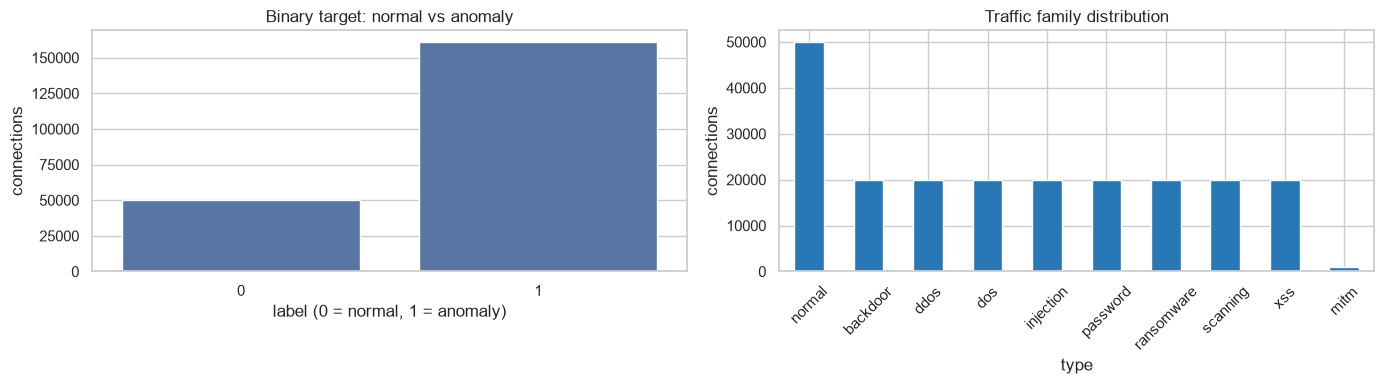

Anomaly rate: 76.31%
Rows where label and type disagree with the expected normal/anomaly mapping:
0


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=raw, x="label", ax=axes[0])
axes[0].set_title("Binary target: normal vs anomaly")
axes[0].set_xlabel("label (0 = normal, 1 = anomaly)")
axes[0].set_ylabel("connections")

raw["type"].value_counts().plot(kind="bar", ax=axes[1], color="#2878b5")
axes[1].set_title("Traffic family distribution")
axes[1].set_xlabel("type")
axes[1].set_ylabel("connections")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Anomaly rate:", f"{raw['label'].astype(int).mean():.2%}")
print("Rows where label and type disagree with the expected normal/anomaly mapping:")
print(((raw["label"].astype(int) == 0) != (raw["type"] == "normal")).sum())

## 3. Data preparation

This stage converts the raw observations into a modeling-ready representation without allowing information from the evaluation data to influence training. The order is deliberate: clean and select columns, split the observations, then fit transformations only on the training partition.

### 3.1 Clean the schema and select feature roles

The source uses `-` for unavailable protocol-specific values; these are loaded as `NaN` because they usually mean not applicable rather than a real measured value. Raw endpoint identifiers are retained in `investigation_context` for analyst use but excluded from the generalizable modeling table. `label` is the primary binary target and `type` remains a descriptive secondary target.

In [15]:
# Keep endpoint identifiers available for later analyst investigation, but do not use
# them as predictors. Including them could make the model memorize network-specific
# addresses and ports, which would inflate offline performance and hurt generalization.
investigation_context = raw[identifier_columns].copy()

# Build the modeling table explicitly. The primary target is retained here; the
# descriptive `type` column is excluded so the binary model cannot learn from a
# label-derived field.
model_columns = [
    column for column in raw.columns
    if column not in identifier_columns + target_columns
]
model_data = raw[model_columns + ["label"]].copy()

# A compact integer target is sufficient for binary classification and avoids treating
# the target as a continuous measurement.
model_data["label"] = model_data["label"].astype("int8")

# Numeric and categorical features need different preparation strategies. Selecting
# by dtype lets the ColumnTransformer apply the correct operation to each group.
feature_numeric_columns = model_data.drop(columns="label").select_dtypes(include="number").columns.tolist()
feature_categorical_columns = model_data.drop(columns="label").select_dtypes(exclude="number").columns.tolist()

assert set(target_columns).issubset(raw.columns)
assert not set(identifier_columns).intersection(model_columns)
assert model_data["label"].isin([0, 1]).all()
assert len(model_data) == len(raw)

print(f"Modeling table: {model_data.shape[0]:,} rows x {model_data.shape[1]} columns")
print(f"Numeric features: {len(feature_numeric_columns)}")
print(f"Categorical features: {len(feature_categorical_columns)}")
print("Excluded identifiers:", identifier_columns)
print("Remaining missing values:", int(model_data.isna().sum().sum()))

model_data.head()

Modeling table: 211,043 rows x 39 columns
Numeric features: 17
Categorical features: 21
Excluded identifiers: ['src_ip', 'src_port', 'dst_ip', 'dst_port']
Remaining missing values: 4384861


,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_query,dns_qclass,dns_qtype,dns_rcode,dns_AA,dns_RD,dns_RA,dns_rejected,ssl_version,ssl_cipher,ssl_resumed,ssl_established,ssl_subject,ssl_issuer,http_trans_depth,http_method,http_uri,http_version,http_request_body_len,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label
0,tcp,NaN,290.371539,101568,2592,OTH,0,108,108064,31,3832,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1
1,tcp,NaN,0.000102,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1
2,tcp,NaN,0.000148,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1
3,tcp,NaN,0.000113,0,0,REJ,0,1,48,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1
4,tcp,NaN,0.000130,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1


### 3.2 Split before transformation

The data is split before imputation, encoding, or scaling. Stratification preserves the observed anomaly rate in both partitions, which is important when attacks are less common than normal traffic. The transformations are fitted only after this split so that test-set statistics cannot leak into training.

In [16]:
from sklearn.model_selection import train_test_split

feature_data = model_data.drop(columns="label")
target_data = model_data["label"]

# A stratified random split gives a first, reproducible benchmark while preserving
# the binary class ratio. `random_state` makes comparisons repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    feature_data,
    target_data,
    test_size=0.20,
    random_state=42,
    stratify=target_data,
)

# Keep the secondary traffic-family label aligned by index. It is used for analysis,
# not as a predictor of the binary anomaly label.
type_train = raw.loc[X_train.index, "type"]
type_test = raw.loc[X_test.index, "type"]

assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(model_data)
assert y_train.value_counts(normalize=True).sort_index().equals(
    target_data.loc[X_train.index].value_counts(normalize=True).sort_index()
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "anomaly_rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])

print(split_summary)
print(f"Training features: {X_train.shape[1]}")
print(f"Training missing values: {int(X_train.isna().sum().sum()):,}")
print(f"Test missing values: {int(X_test.isna().sum().sum()):,}")

         rows  anomaly_rate
train  168834      0.763081
test    42209      0.763084
Training features: 38
Training missing values: 3,508,338
Test missing values: 876,523


### 3.3 Transform features and define the baseline

Numeric values use median imputation because network measurements can contain missing values and extreme outliers; the median is less sensitive to those outliers than the mean. Standardization puts numeric variables on comparable scales, which helps logistic regression optimize stable coefficients.

Categorical values use most-frequent imputation for missing categories, then one-hot encoding. One-hot encoding avoids inventing an artificial ordering such as `tcp > udp`, while `handle_unknown="ignore"` allows the model to score a category that was absent from training.

All transformations are placed inside a pipeline. This ensures that imputation statistics, category levels, and scaling parameters are learned from training data only.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing is robust to missing measurements and puts features on a
# comparable scale. This is especially important for a linear model because a large-
# magnitude feature could otherwise dominate the coefficient optimization.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical values are represented as independent indicator columns rather than
# arbitrary integers, because protocol/service names have no natural numeric order.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# ColumnTransformer applies each branch only to the compatible columns and combines
# the results into one feature matrix without manually mutating the raw dataframe.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, feature_numeric_columns),
    ("categorical", categorical_pipeline, feature_categorical_columns),
])

# Logistic regression is the interpretable baseline: its coefficients provide a
# direction and strength for each transformed feature. `class_weight="balanced"`
# increases the influence of the minority class, which is appropriate when missing
# an anomaly is more costly than reviewing an extra alert.
baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="liblinear",
        random_state=42,
    )),
])

baseline_pipeline.fit(X_train, y_train)
y_pred = baseline_pipeline.predict(X_test)
y_score = baseline_pipeline.predict_proba(X_test)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3))
print(f"Average precision (PR-AUC): {average_precision_score(y_test, y_score):.3f}")

Confusion matrix:
[[ 9813   187]
 [ 2886 29323]]

Classification report:
              precision    recall  f1-score   support

           0      0.773     0.981     0.865     10000
           1      0.994     0.910     0.950     32209

    accuracy                          0.927     42209
   macro avg      0.883     0.946     0.907     42209
weighted avg      0.941     0.927     0.930     42209

Average precision (PR-AUC): 0.996


## 4. Modeling and evaluation

Modeling starts with an interpretable baseline and then adds a nonlinear comparison. Evaluation is separated from preparation so that model quality is measured only after the feature table and train-only transformations have been defined.

### 4.1 Compare interpretable and nonlinear models

In [18]:
from sklearn.base import clone
from sklearn.metrics import f1_score, precision_score, recall_score
from xgboost import XGBClassifier

# XGBoost is a gradient-boosted decision-tree model. Unlike logistic regression, it
# can learn nonlinear thresholds and interactions, such as a suspicious combination
# of connection state, packet counts, and protocol metadata.
class_counts = y_train.value_counts()
scale_pos_weight = class_counts[0] / class_counts[1]

# The same preprocessor is cloned so XGBoost receives exactly the same information as
# the baseline. Cloning also prevents the two models from sharing fitted state.
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=2,
        reg_lambda=1.0,
        # Weighting the minority class makes the boosting objective pay more attention
        # to anomalous connections instead of optimizing mostly for normal traffic.
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
    )),
])

xgb_pipeline.fit(X_train, y_train)
y_xgb_pred = xgb_pipeline.predict(X_test)
y_xgb_score = xgb_pipeline.predict_proba(X_test)[:, 1]

# PR-AUC is emphasized because the security question is how well high-risk alerts
# are ranked, especially when the classes are not equally costly. Precision, recall,
# and F1 show the alert-quality tradeoff at the current 0.5 decision threshold.
model_comparison = pd.DataFrame([
    {
        "model": "Logistic regression",
        "pr_auc": average_precision_score(y_test, y_score),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
    },
    {
        "model": "XGBoost",
        "pr_auc": average_precision_score(y_test, y_xgb_score),
        "precision": precision_score(y_test, y_xgb_pred, zero_division=0),
        "recall": recall_score(y_test, y_xgb_pred, zero_division=0),
        "f1": f1_score(y_test, y_xgb_pred, zero_division=0),
    },
]).set_index("model")

print(f"XGBoost scale_pos_weight: {scale_pos_weight:.2f}")
print(model_comparison.round(3))
print("\nXGBoost classification report:")
print(classification_report(y_test, y_xgb_pred, digits=3, zero_division=0))

XGBoost scale_pos_weight: 0.31
                     pr_auc  precision  recall     f1
model                                                
Logistic regression   0.996      0.994   0.910  0.950
XGBoost               1.000      0.999   0.998  0.999

XGBoost classification report:
              precision    recall  f1-score   support

           0      0.995     0.997     0.996     10000
           1      0.999     0.998     0.999     32209

    accuracy                          0.998     42209
   macro avg      0.997     0.998     0.997     42209
weighted avg      0.998     0.998     0.998     42209



### 3.4 Optional dimensionality reduction

The reference workflow demonstrates PCA as a general technique. It is not required for this baseline: one-hot encoding produces a sparse feature matrix, and reducing it could weaken interpretability. If dimensionality reduction is needed for a later model or visualization, `TruncatedSVD` on the sparse transformed matrix is more appropriate than ordinary PCA, and it must also be fitted on training data only.

### 4.2 Generalization and validation strategy

A random split provides a useful first benchmark, but repeated or near-duplicate flows can make that benchmark optimistic. The next checks measure duplicate risk and evaluate a grouped split in which identical feature rows cannot appear in both train and test.

In [19]:
feature_strings = feature_data.astype("string").fillna("<MISSING>")
row_hashes = pd.util.hash_pandas_object(feature_strings, index=False)

train_hashes = row_hashes.loc[X_train.index]
test_hashes = row_hashes.loc[X_test.index]
shared_hashes = set(train_hashes).intersection(test_hashes)
test_cross_split_duplicate_mask = test_hashes.isin(shared_hashes)

duplicate_groups = (
    pd.DataFrame({"row_hash": row_hashes, "label": target_data})
    .groupby("row_hash", as_index=False)
    .agg(rows=("label", "size"), label_count=("label", "nunique"))
)

exact_duplicate_rows = int(feature_strings.duplicated(keep=False).sum())
conflicting_duplicate_groups = int((duplicate_groups["label_count"] > 1).sum())
cross_split_duplicate_rows = int(test_cross_split_duplicate_mask.sum())
cross_split_duplicate_rate = cross_split_duplicate_rows / len(X_test)

print(f"Rows belonging to an exact duplicate feature group: {exact_duplicate_rows:,}")
print(f"Exact duplicate groups with conflicting labels: {conflicting_duplicate_groups:,}")
print(f"Test rows duplicated in training features: {cross_split_duplicate_rows:,} ({cross_split_duplicate_rate:.2%})")

if conflicting_duplicate_groups:
    print("Conflicting duplicate groups (first 6):")
    print(duplicate_groups.loc[duplicate_groups["label_count"] > 1].head(6))

Rows belonging to an exact duplicate feature group: 124,413
Exact duplicate groups with conflicting labels: 6
Test rows duplicated in training features: 24,654 (58.41%)
Conflicting duplicate groups (first 6):
                   row_hash  rows  label_count
4634     918141604109666411    52            2
14607   2876659330968614728  1605            2
16318   3207693068723981123  1474            2
25733   5024555104560273579   776            2
80598  15853599861004413736    67            2
88393  17399259035622177675  2886            2


### 4.3 Check duplicate and near-duplicate risk

Repeated flow records can make a random split look stronger than deployment on genuinely new traffic. This audit checks exact feature-row duplication between train and test and verifies whether identical feature rows have consistent labels. A grouped split based on the feature-row hash provides a stricter generalization check.

In [20]:
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
group_train_positions, group_test_positions = next(
    splitter.split(feature_data, target_data, groups=row_hashes)
)

X_group_train = feature_data.iloc[group_train_positions]
X_group_test = feature_data.iloc[group_test_positions]
y_group_train = target_data.iloc[group_train_positions]
y_group_test = target_data.iloc[group_test_positions]

group_train_hashes = set(row_hashes.iloc[group_train_positions])
group_test_hashes = set(row_hashes.iloc[group_test_positions])

assert group_train_hashes.isdisjoint(group_test_hashes)

print(pd.DataFrame({
    "rows": [len(X_group_train), len(X_group_test)],
    "anomaly_rate": [y_group_train.mean(), y_group_test.mean()],
}, index=["group_train", "group_test"]))

# Refit the same pipeline so preprocessing remains isolated to grouped training data.
grouped_baseline_pipeline = clone(baseline_pipeline)
grouped_baseline_pipeline.fit(X_group_train, y_group_train)
y_group_pred = grouped_baseline_pipeline.predict(X_group_test)
y_group_score = grouped_baseline_pipeline.predict_proba(X_group_test)[:, 1]

print("Grouped-split classification report:")
print(classification_report(y_group_test, y_group_pred, digits=3))
print(f"Grouped-split average precision (PR-AUC): {average_precision_score(y_group_test, y_group_score):.3f}")

               rows  anomaly_rate
group_train  171602      0.759239
group_test    39441      0.779798
Grouped-split classification report:
              precision    recall  f1-score   support

           0      0.540     0.976     0.695      8685
           1      0.991     0.766     0.864     30756

    accuracy                          0.812     39441
   macro avg      0.766     0.871     0.780     39441
weighted avg      0.892     0.812     0.827     39441

Grouped-split average precision (PR-AUC): 0.997


### 4.4 Inspect threshold tradeoffs and attack-family recall

A probability threshold of 0.5 is only a default. The table below is diagnostic; the final threshold must be selected on validation data rather than on the test set. For intrusion detection, the threshold should reflect the cost of missed attacks versus analyst workload. Family-level recall helps identify attack types that the overall score may hide.

In [21]:
from sklearn.metrics import f1_score, precision_score, recall_score

thresholds = [round(value, 2) for value in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]]
threshold_rows = []

for threshold in thresholds:
    threshold_pred = (y_group_score >= threshold).astype("int8")
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_group_test, threshold_pred),
        "recall": recall_score(y_group_test, threshold_pred),
        "f1": f1_score(y_group_test, threshold_pred),
    })

threshold_summary = pd.DataFrame(threshold_rows)
print(threshold_summary.round(3).to_string(index=False))

family_evaluation = pd.DataFrame({
    "type": raw.loc[X_group_test.index, "type"].to_numpy(),
    "label": y_group_test.to_numpy(),
    "prediction": y_group_pred,
    "score": y_group_score,
})

attack_family_recall = (
    family_evaluation.loc[family_evaluation["label"] == 1]
    .groupby("type")
    .agg(
        rows=("label", "size"),
        recall=("prediction", "mean"),
        mean_score=("score", "mean"),
    )
    .sort_values("recall")
)

print("\nGrouped-holdout recall by attack family:")
print(attack_family_recall.round(3).to_string())

 threshold  precision  recall    f1
       0.2      0.992   0.991 0.991
       0.3      0.991   0.778 0.871
       0.4      0.991   0.771 0.867
       0.5      0.991   0.766 0.864
       0.6      0.992   0.764 0.863
       0.7      0.994   0.756 0.859
       0.8      0.994   0.755 0.858
       0.9      0.994   0.753 0.857

Grouped-holdout recall by attack family:
            rows  recall  mean_score
type                                
ransomware  6866   0.013       0.280
mitm         190   0.747       0.699
dos         3536   0.947       0.942
ddos        4752   0.971       0.969
xss         1814   0.985       0.962
injection   4096   0.994       0.956
scanning     913   0.997       0.990
password    4095   0.998       0.963
backdoor    4494   1.000       1.000


### 4.5 Select an operating threshold without test-set tuning

Use a second grouped split inside the grouped training partition for threshold selection. The final model is then refit on all grouped training rows, and the selected threshold is evaluated once on the untouched grouped test set. This prevents the test set from becoming part of the decision rule.

In [22]:
inner_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=43)
inner_train_positions, validation_positions = next(
    inner_splitter.split(
        X_group_train,
        y_group_train,
        groups=row_hashes.iloc[group_train_positions].to_numpy(),
    )
)

X_inner_train = X_group_train.iloc[inner_train_positions]
X_validation = X_group_train.iloc[validation_positions]
y_inner_train = y_group_train.iloc[inner_train_positions]
y_validation = y_group_train.iloc[validation_positions]

threshold_model = clone(baseline_pipeline)
threshold_model.fit(X_inner_train, y_inner_train)
y_validation_score = threshold_model.predict_proba(X_validation)[:, 1]

validation_threshold_rows = []
for threshold in thresholds:
    validation_prediction = (y_validation_score >= threshold).astype("int8")
    validation_threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_validation, validation_prediction),
        "recall": recall_score(y_validation, validation_prediction),
        "f1": f1_score(y_validation, validation_prediction),
    })

validation_threshold_summary = pd.DataFrame(validation_threshold_rows)
selected_threshold = float(
    validation_threshold_summary.loc[
        validation_threshold_summary["f1"].idxmax(), "threshold"
    ]
)

final_grouped_model = clone(baseline_pipeline)
final_grouped_model.fit(X_group_train, y_group_train)
y_final_test_score = final_grouped_model.predict_proba(X_group_test)[:, 1]
y_final_test_prediction = (y_final_test_score >= selected_threshold).astype("int8")

print(validation_threshold_summary.round(3).to_string(index=False))
print(f"Selected validation threshold: {selected_threshold:.2f}")
print("\nFinal grouped-test classification report:")
print(classification_report(y_group_test, y_final_test_prediction, digits=3))
print(
    "Final grouped-test average precision (PR-AUC): "
    f"{average_precision_score(y_group_test, y_final_test_score):.3f}"
)

 threshold  precision  recall    f1
       0.2      0.990   0.986 0.988
       0.3      0.991   0.943 0.967
       0.4      0.992   0.938 0.964
       0.5      0.992   0.932 0.961
       0.6      0.992   0.927 0.959
       0.7      0.994   0.920 0.956
       0.8      0.994   0.916 0.953
       0.9      0.994   0.914 0.952
Selected validation threshold: 0.20

Final grouped-test classification report:
              precision    recall  f1-score   support

           0      0.969     0.971     0.970      8685
           1      0.992     0.991     0.991     30756

    accuracy                          0.987     39441
   macro avg      0.980     0.981     0.981     39441
weighted avg      0.987     0.987     0.987     39441

Final grouped-test average precision (PR-AUC): 0.997
